# Task 1: Load and Preprocess the Fashion MNIST Dataset
We will import the necessary PyTorch libraries and download the Fashion MNIST dataset. We'll set up training and testing dataloaders with standard preprocessing (converting to tensors and normalizing).

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Define transforms
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# Download and load the training and test data
train_set = datasets.FashionMNIST('~/.pytorch/F_MNIST_data/', download=True, train=True, transform=transform)
train_loader = DataLoader(train_set, batch_size=64, shuffle=True)

test_set = datasets.FashionMNIST('~/.pytorch/F_MNIST_data/', download=True, train=False, transform=transform)
test_loader = DataLoader(test_set, batch_size=64, shuffle=False)

# Class names map
classes = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

# Check a batch
images, labels = next(iter(train_loader))
print(f"Image batch shape: {images.shape}")
print(f"Label batch shape: {labels.shape}")

Using device: cuda


100%|██████████| 26.4M/26.4M [00:02<00:00, 11.3MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 203kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.75MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 3.93MB/s]

Image batch shape: torch.Size([64, 1, 28, 28])
Label batch shape: torch.Size([64])


# Task 2: Build the PyTorch Models
We will define two models to clearly compare the effects of regularization:
1. **Baseline Model**: A deep neural network without any regularization.
2. **Regularized Model**: The same architecture but with `Dropout` layers added.

In [2]:
class BaselineModel(nn.Module):
    def __init__(self):
        super(BaselineModel, self).__init__()
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.classifier(x)

class RegularizedModel(nn.Module):
    def __init__(self, dropout_rate=0.4):
        super(RegularizedModel, self).__init__()
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 512),
            nn.ReLU(),
            nn.Dropout(p=dropout_rate),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(p=dropout_rate),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(p=dropout_rate),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.classifier(x)

# Task 3: Train and Execute the Models
We will define a training loop helper function. To implement **L2 Weight Decay**, we will utilize the `weight_decay` parameter inside PyTorch's `optim.Adam` optimizer for our Regularized Model, while leaving the baseline model optimizer without weight decay.

In [3]:
def train_and_evaluate_model(model, optimizer, train_loader, test_loader, epochs=15):
    criterion = nn.CrossEntropyLoss()
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    for epoch in range(epochs):
        # Training Phase
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

        epoch_train_loss = running_loss / len(train_loader.dataset)
        epoch_train_acc = (correct / total) * 100

        # Validation Phase
        model.eval()
        val_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for images, labels in test_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * images.size(0)
                _, predicted = outputs.max(1)
                val_total += labels.size(0)
                val_correct += predicted.eq(labels).sum().item()

        epoch_val_loss = val_loss / len(test_loader.dataset)
        epoch_val_acc = (val_correct / val_total) * 100

        history['train_loss'].append(epoch_train_loss)
        history['val_loss'].append(epoch_val_loss)
        history['train_acc'].append(epoch_train_acc)
        history['val_acc'].append(epoch_val_acc)

        print(f"Epoch {epoch+1:02d}/{epochs} | "
              f"Train Loss: {epoch_train_loss:.4f} - Train Acc: {epoch_train_acc:.2f}% | "
              f"Val Loss: {epoch_val_loss:.4f} - Val Acc: {epoch_val_acc:.2f}%")

    return history

# --- 1. Train Baseline Model (No Dropout, No Weight Decay) ---
print("=== Training Baseline Model ===")
baseline_model = BaselineModel().to(device)
baseline_optimizer = optim.Adam(baseline_model.parameters(), lr=0.001)
baseline_history = train_and_evaluate_model(baseline_model, baseline_optimizer, train_loader, test_loader, epochs=15)

# --- 2. Train Regularized Model (With Dropout & L2 Weight Decay) ---
print("\n=== Training Regularized Model (Dropout + L2 Decay) ===")
reg_model = RegularizedModel(dropout_rate=0.3).to(device)
# Implementing L2 Weight Decay using weight_decay parameter
reg_optimizer = optim.Adam(reg_model.parameters(), lr=0.001, weight_decay=1e-4)
reg_history = train_and_evaluate_model(reg_model, reg_optimizer, train_loader, test_loader, epochs=15)

=== Training Baseline Model ===
Epoch 01/15 | Train Loss: 0.5037 - Train Acc: 81.49% | Val Loss: 0.4425 - Val Acc: 84.22%
Epoch 02/15 | Train Loss: 0.3730 - Train Acc: 86.31% | Val Loss: 0.3953 - Val Acc: 85.78%
Epoch 03/15 | Train Loss: 0.3347 - Train Acc: 87.68% | Val Loss: 0.3766 - Val Acc: 86.30%
Epoch 04/15 | Train Loss: 0.3072 - Train Acc: 88.58% | Val Loss: 0.3419 - Val Acc: 87.41%
Epoch 05/15 | Train Loss: 0.2863 - Train Acc: 89.30% | Val Loss: 0.3579 - Val Acc: 87.27%
Epoch 06/15 | Train Loss: 0.2715 - Train Acc: 89.90% | Val Loss: 0.3455 - Val Acc: 87.30%
Epoch 07/15 | Train Loss: 0.2567 - Train Acc: 90.44% | Val Loss: 0.3348 - Val Acc: 88.29%
Epoch 08/15 | Train Loss: 0.2402 - Train Acc: 91.02% | Val Loss: 0.3363 - Val Acc: 88.59%
Epoch 09/15 | Train Loss: 0.2313 - Train Acc: 91.27% | Val Loss: 0.3273 - Val Acc: 88.73%
Epoch 10/15 | Train Loss: 0.2193 - Train Acc: 91.78% | Val Loss: 0.3455 - Val Acc: 88.00%
Epoch 11/15 | Train Loss: 0.2068 - Train Acc: 92.17% | Val Loss: 0.3

# Task 4 & 5: Evaluate & Visualize Results
Now we will plot and compare the Loss curves and Accuracy performance of both models to observe how Dropout and L2 Regularization successfully mitigate overfitting.

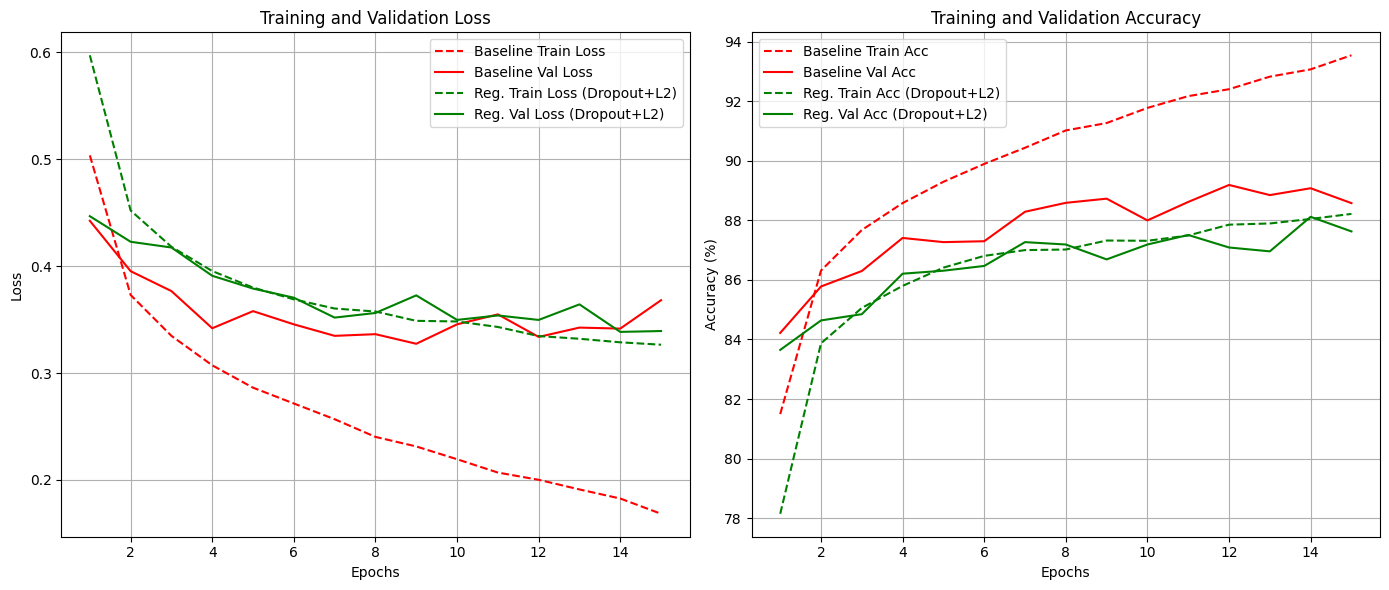

In [4]:
epochs = range(1, 16)

plt.figure(figsize=(14, 6))

# Plot Loss comparison
plt.subplot(1, 2, 1)
plt.plot(epochs, baseline_history['train_loss'], 'r--', label='Baseline Train Loss')
plt.plot(epochs, baseline_history['val_loss'], 'r-', label='Baseline Val Loss')
plt.plot(epochs, reg_history['train_loss'], 'g--', label='Reg. Train Loss (Dropout+L2)')
plt.plot(epochs, reg_history['val_loss'], 'g-', label='Reg. Val Loss (Dropout+L2)')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plot Accuracy comparison
plt.subplot(1, 2, 2)
plt.plot(epochs, baseline_history['train_acc'], 'r--', label='Baseline Train Acc')
plt.plot(epochs, baseline_history['val_acc'], 'r-', label='Baseline Val Acc')
plt.plot(epochs, reg_history['train_acc'], 'g--', label='Reg. Train Acc (Dropout+L2)')
plt.plot(epochs, reg_history['val_acc'], 'g-', label='Reg. Val Acc (Dropout+L2)')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()